In [61]:
import sys
import pathlib
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import Descriptors
from rdkit.Chem import rdmolfiles
import seaborn as sns

In [30]:
df = pd.read_csv(f"data/ligend_smiles_cononical.csv", index_col=0, low_memory=False)

In [57]:
def mol_from_row(row, col_name="sdf"):
    smiles = df.loc[df['ID'] == row['ID'], 'SMILES']
    try:
        # print(smiles.item())
        mol = Chem.MolFromSmiles(smiles.item())
    except:
        mol = None
    return mol
    
##############################################################################
# Physicochemical feature functions
##############################################################################
FEATURES = {
    "MolWt"          : Descriptors.MolWt,
    "ExactMolWt"     : Descriptors.ExactMolWt,
    "NumRotatable"   : Descriptors.NumRotatableBonds,
    "TPSA"           : Descriptors.TPSA,
    "LogP"           : Descriptors.MolLogP,
    "HBA"            : Descriptors.NumHAcceptors,
    "HBD"            : Descriptors.NumHDonors,
}

def featurise(df, group_name, mol_col="sdf"):
    """Return a new DataFrame with one row per compound and physchem columns."""
    out_rows = []
    for idx, row in df.iterrows():
        mol = mol_from_row(row, mol_col)
        if mol is None:
            print(f"[warning] no molecule parsed at row {idx} in {group_name}")
            continue

        feats = {fname: f(mol) for fname, f in FEATURES.items()}
        feats.update(group=group_name, idx=idx)
        out_rows.append(feats)

    return pd.DataFrame(out_rows)


In [59]:
file1 = "stab.csv"
file2 = "destab.csv"


df1 = pd.read_csv(file1)
df2 = pd.read_csv(file2)

group1_name = pathlib.Path(file1).stem      # e.g. “stabilisers”
group2_name = pathlib.Path(file2).stem      # e.g. “destabilisers”

feat1 = featurise(df1, group1_name)
feat2 = featurise(df2, group2_name)

combined = pd.concat([feat1, feat2], ignore_index=True)
combined.to_csv("physchem_descriptors.csv", index=False)
print("Wrote physchem_descriptors.csv")

IndentationError: unexpected indent (1164250843.py, line 23)

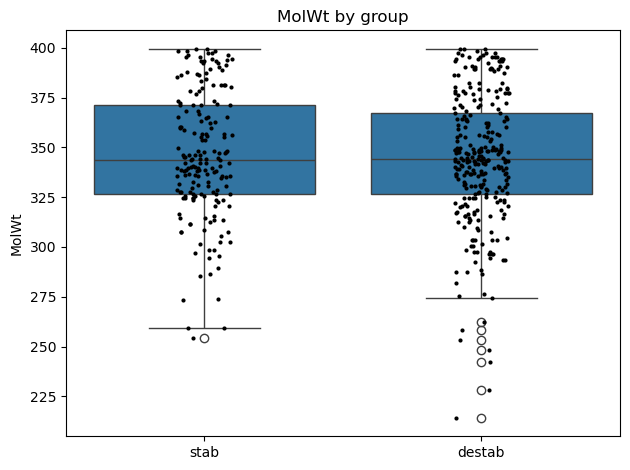

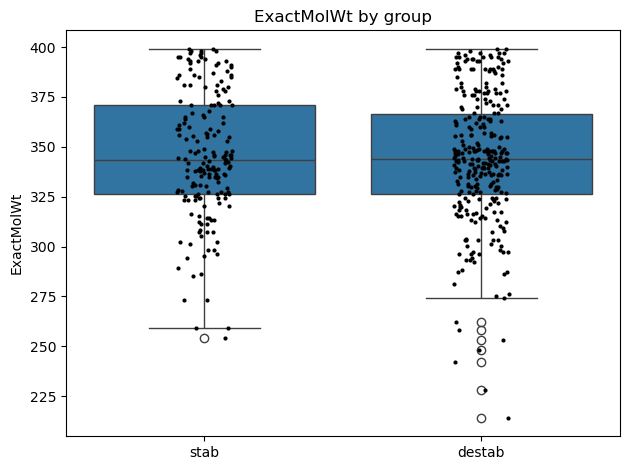

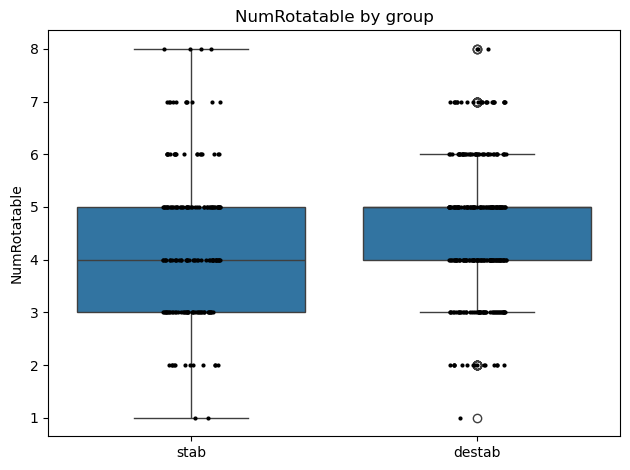

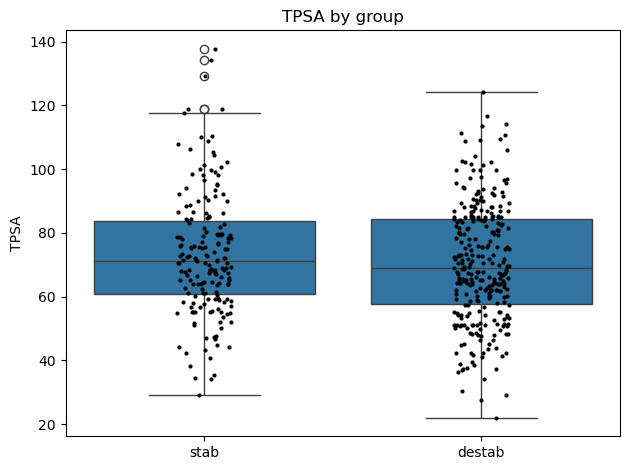

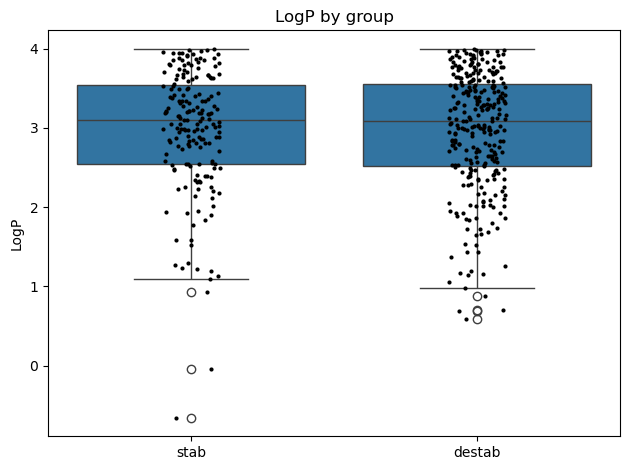

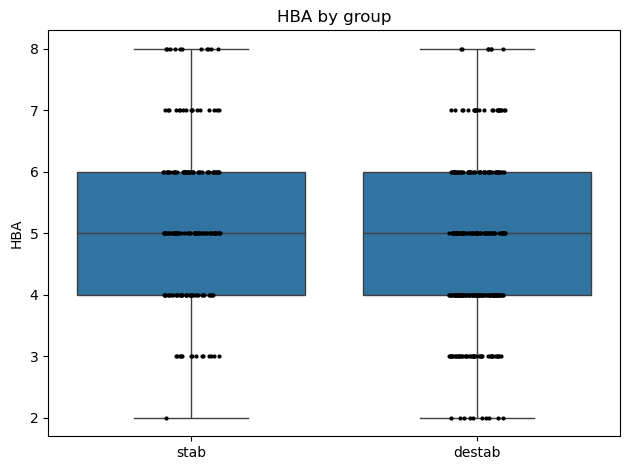

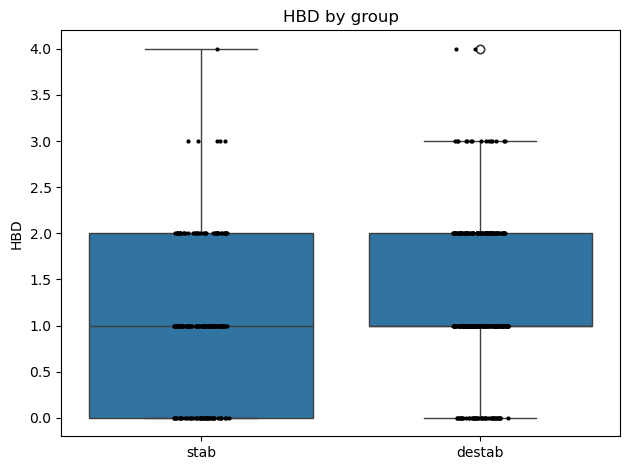

In [64]:
for col in FEATURES.keys():
        
    plt.figure()  # one figure per descriptor
    sns.boxplot(data=combined, x="group", y=col)  # violin without internal boxplot
    sns.stripplot(data=combined, x="group", y=col, color="black", size=3, jitter=True)  # show individual dots
    plt.title(f"{col} by group")
    plt.xlabel("")
    plt.ylabel(col)
    plt.tight_layout()

plt.show()